# **Cross-Family LLM Stitching: Comparing Reconstruction and Prediction-Based Objectives**

*COMS 4705 - Natural Language Processing - Final Project*

### **Authors**

Caroline Zhang (cz2977@columbia.edu)

Siddharth Grover (sg4792@columbia.edu)

Edwin Argudo (eaa2193@columbia.edu)

### **GitHub Repo**

https://github.com/edwin-a14/coms-4705-project-cross-model-stitching

## 1. Install Dependencies

In [1]:

%pip install -q \
    "transformers>=4.45,<5" \
    "accelerate>=1.0" \
    "datasets>=3,<5" \
    "huggingface_hub>=0.34,<1.0" \
    safetensors

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.31.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.42.1 requires huggingface-hub<3.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.


## 2. Connect to Google Drive

In order to connect to the shared Google Drive folder, you need to create a shortcut from the shared folder into your personal My Drive. Do the following:
1. Go to drive.google.com
2. Locate the shared `coms-4705-project` folder, click inside
3. Click on the down-arrow next to the folder name
4. **Organize > Add shortcut > All Locations > My Drive**

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [17]:
import os

DRIVE_PROJECT_DIR = '/content/drive/MyDrive/coms-4705-project'

os.chdir(DRIVE_PROJECT_DIR)
print(f'Working directory set to: {os.getcwd()}')

files = os.listdir('.')
print(f'Read access confirmed, found {len(files)} items')

Working directory set to: /content/drive/MyDrive/coms-4705-project
Read access confirmed, found 0 items


## 3. Project Configuration

`meta-llama/Llama-3.2-3B` requires us to accept license before being able to access it on HuggingFace, so you'll need to go to https://huggingface.co/meta-llama/Llama-3.2-3B and fill out the "Request Access" form with your personal information.

In [4]:
MODELS = {
    "llama": "meta-llama/Llama-3.2-3B",  # NOTE: this model requires accepted license/access
    "qwen":  "Qwen/Qwen2.5-3B"
}

## 4. Verify HuggingFace access

To connect HuggingFace to this notebook:

1. Go to https://huggingface.co/settings/tokens
2. Create an Access Token with write privileges
3. In this notebook, go to the **Secrets** tab, and add a secret with name: `HF_TOKEN`, value: `<Access Token>`, and turn on notebook access
4. Restart the runtime, and run the cells below to verify access

In [5]:
from google.colab import userdata
from huggingface_hub import login, whoami, hf_hub_download
from huggingface_hub.utils import GatedRepoError

try:
    hf_token = userdata.get("HF_TOKEN")
    login(token=hf_token)

    user = whoami()
    print(f"Authenticated as: {user['name']}")

    config_path = hf_hub_download(
        repo_id=MODELS["llama"],
        filename="config.json"
    )
    print(f"Access confirmed for {MODELS["llama"]}!")

except userdata.SecretNotFoundError:
    print("Secret 'HF_TOKEN' not found. Add it in the Colab Secrets sidebar.")
except userdata.NotebookAccessError:
    print("Notebook access disabled. Toggle on 'Notebook access' for HF_TOKEN.")
except GatedRepoError:
    print(f"Access denied for {MODELS["llama"]}. Accept the license on its Hugging Face page.")

Authenticated as: edlose


config.json:   0%|          | 0.00/844 [00:00<?, ?B/s]

Access confirmed for meta-llama/Llama-3.2-3B!


## 5. Verify Model Configuration and Tokenization

In [6]:

from transformers import AutoConfig, AutoTokenizer

qwen_id = MODELS["qwen"]

config = AutoConfig.from_pretrained(qwen_id)
qwen_tokenizer = AutoTokenizer.from_pretrained(qwen_id)

print("Model:", qwen_id)
print("Hidden size:", config.hidden_size)
print("Number of layers:", config.num_hidden_layers)
print("Attention heads:", config.num_attention_heads)
print("KV heads:", config.num_key_value_heads)
print("Vocabulary size:", config.vocab_size)

prompt = "The capital of France is"

tokens = qwen_tokenizer.tokenize(prompt)

print("\nPrompt:", prompt)
print("Tokens:", tokens)
print("Token count:", len(tokens))


config.json:   0%|          | 0.00/683 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

Model: Qwen/Qwen2.5-3B
Hidden size: 2048
Number of layers: 36
Attention heads: 16
KV heads: 2
Vocabulary size: 151936

Prompt: The capital of France is
Tokens: ['The', 'Ġcapital', 'Ġof', 'ĠFrance', 'Ġis']
Token count: 5


In [32]:

from transformers import AutoConfig, AutoTokenizer

llama_id = MODELS["llama"]

config = AutoConfig.from_pretrained(llama_id)
llama_tokenizer = AutoTokenizer.from_pretrained(llama_id)

print("Model:", llama_id)
print("Hidden size:", config.hidden_size)
print("Number of layers:", config.num_hidden_layers)
print("Attention heads:", config.num_attention_heads)
print("KV heads:", config.num_key_value_heads)
print("Vocabulary size:", config.vocab_size)

prompt = "The capital of France is"
tokens = llama_tokenizer.tokenize(prompt)

print("\nPrompt:", prompt)
print("Tokens:", tokens)
print("Token count:", len(tokens))

Model: meta-llama/Llama-3.2-3B
Hidden size: 3072
Number of layers: 28
Attention heads: 24
KV heads: 8
Vocabulary size: 128256

Prompt: The capital of France is
Tokens: ['The', 'Ġcapital', 'Ġof', 'ĠFrance', 'Ġis']
Token count: 5


## 6. Load LAMBADA Dataset

In [8]:
from datasets import load_dataset

dataset = load_dataset(
    "cimec/lambada",
    split="validation",
    streaming=True
)

README.md: 0.00B [00:00, ?B/s]

In [33]:

from transformers import AutoTokenizer

# Get one LAMBADA example
example = next(iter(dataset))
text = example["text"].rstrip()

# Separate the final word from the context
prefix, target = text.rsplit(" ", 1)

# Tokenize both
prefix_ids = qwen_tokenizer.encode(prefix)
full_ids = qwen_tokenizer.encode(text)

# Check whether the token boundary is consistent
valid = full_ids[:len(prefix_ids)] == prefix_ids

print("Prefix:", prefix[-100:])
print("Target word:", target)
print("Valid token boundary:", valid)

if valid:
    next_token_id = full_ids[len(prefix_ids)]
    print("Next token:", repr(qwen_tokenizer.decode([next_token_id])))


Prefix: . brian and max were a lot of fun and always made her laugh as they hoisted her up to the top of the
Target word: cake
Valid token boundary: True
Next token: ' cake'


## 7. Smoke Test - Extract Qwen's hidden representation

In [22]:
import torch
from transformers import AutoModelForCausalLM

assert torch.cuda.is_available(), "Please enable a GPU runtime"

qwen = AutoModelForCausalLM.from_pretrained(
    MODELS["qwen"],
    torch_dtype=torch.float16,
    device_map="auto"
)

qwen.eval()

qwen_tokenizer.truncation_side = "left"

# Using the prefix from our LAMBADA example
inputs = qwen_tokenizer(
    prefix,
    return_tensors="pt",
    truncation=True,
    max_length=256
).to(qwen.device)

captured = {}

def capture_activation(module, args):
    captured["hidden"] = args[0][:, -1, :].detach()

hook = qwen.model.norm.register_forward_pre_hook(
    capture_activation
)

try:
    with torch.no_grad():
        outputs = qwen(**inputs, use_cache=False)
finally:
    hook.remove()

h_qwen = captured["hidden"]

print("Hidden representation:", h_qwen.shape)
print("First 10 values:", h_qwen[0, :10])


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Hidden representation: torch.Size([1, 2048])
First 10 values: tensor([ 0.2092, -3.7148, -2.5078, -6.7461,  2.6445,  2.0332, 21.5000,  2.8613,
         2.6641,  3.8984], device='cuda:0', dtype=torch.float16)


### 7.1 Sanity Check - Ensure captured activation `h_qwen` can reproduce Qwen's original next-token predictions

In [23]:
# Reconstruct the logits from our captured activation
with torch.no_grad():
    reconstructed_logits = qwen.lm_head(
        qwen.model.norm(h_qwen)
    )

# Compare with the logits produced by native Qwen
native_logits = outputs.logits[:, -1, :]

max_diff = (
    reconstructed_logits.float() - native_logits.float()
).abs().max().item()

print("Native logits:", native_logits.shape)
print("Reconstructed logits:", reconstructed_logits.shape)
print("Maximum difference:", max_diff)

print(
    "Predictions match:",
    torch.argmax(native_logits, dim=-1).item()
    == torch.argmax(reconstructed_logits, dim=-1).item()
)

assert torch.allclose(
    reconstructed_logits.float(),
    native_logits.float(),
    atol=1e-2,
    rtol=1e-3
)


Native logits: torch.Size([1, 151936])
Reconstructed logits: torch.Size([1, 151936])
Maximum difference: 0.0078125
Predictions match: True


### 7.2 Save Qwen's activation and free GPU memory

In [24]:
import gc

h_qwen = h_qwen.cpu()

del qwen, outputs
gc.collect()
torch.cuda.empty_cache()

print("Saved Qwen activation:", h_qwen.shape)

Saved Qwen activation: torch.Size([1, 2048])


## 8. Smoke Test - Extract Llama's hidden representation

In [15]:
from transformers import AutoTokenizer, AutoModelForCausalLM

llama_tokenizer = AutoTokenizer.from_pretrained(MODELS["llama"])

llama = AutoModelForCausalLM.from_pretrained(
    MODELS["llama"],
    torch_dtype=torch.float16,
    device_map="auto"
)

llama.eval()

inputs = llama_tokenizer(
    prefix,
    return_tensors="pt",
    truncation=True,
    max_length=256
).to(llama.device)

captured = {}

def capture_activation(module, args):
    captured["hidden"] = args[0][:, -1, :].detach()

hook = llama.model.norm.register_forward_pre_hook(
    capture_activation
)

try:
    with torch.no_grad():
        _ = llama.model(**inputs, use_cache=False)
finally:
    hook.remove()

h_llama = captured["hidden"].cpu()

print("Llama activation:", h_llama.shape)
print("Qwen activation:", h_qwen.shape)

model.safetensors.index.json: 0.00B [00:00, ?B/s]

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

model-00001-of-00002.safetensors:   0%|          | 0.00/4.97G [00:00<?, ?B/s]

model-00002-of-00002.safetensors:   0%|          | 0.00/1.46G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/185 [00:00<?, ?B/s]

Llama activation: torch.Size([1, 3072])
Qwen activation: torch.Size([1, 2048])


### 8.1 Save activations in Google Drive

In [18]:
from pathlib import Path
import torch

save_dir = Path(DRIVE_PROJECT_DIR) / "activations"
save_dir.mkdir(parents=True, exist_ok=True)

cache_path = save_dir / "smoke_test.pt"

torch.save({
    "prefix": prefix,
    "h_llama": h_llama.detach().cpu(),
    "h_qwen": h_qwen.detach().cpu(),
    "target_token_id": next_token_id,
    "source_model": MODELS["llama"],
    "target_model": MODELS["qwen"],
}, cache_path)

print("Saved to:", cache_path)

Saved to: /content/drive/MyDrive/coms-4705-project/activations/smoke_test.pt


In [25]:
cached = torch.load(
    cache_path,
    map_location="cpu",
    weights_only=True
)

assert cached["h_llama"].shape == (1, 3072)
assert cached["h_qwen"].shape == (1, 2048)

print("Llama:", cached["h_llama"].shape)
print("Qwen:", cached["h_qwen"].shape)
print("Target:", qwen_tokenizer.decode([cached["target_token_id"]]))

Llama: torch.Size([1, 3072])
Qwen: torch.Size([1, 2048])
Target:  cake


### 8.2 Verify both models received the same text

In [26]:
MAX_TOKENS = 256

for name, tok in [
    ("Qwen", qwen_tokenizer),
    ("Llama", llama_tokenizer),
]:
    token_count = len(tok.encode(prefix))
    print(f"{name}: {token_count} tokens")
    print(f"Fits context limit: {token_count <= MAX_TOKENS}")


Qwen: 105 tokens
Fits context limit: True
Llama: 106 tokens
Fits context limit: True


## 9. Reusable Activation Extraction

In [27]:
def extract_activation(model, tokenizer, text, max_tokens=256):
    # Tokenize without truncating the input
    inputs = tokenizer(text, return_tensors="pt")

    if inputs["input_ids"].shape[1] > max_tokens:
        raise ValueError("Input exceeds context limit")

    inputs = inputs.to(model.get_input_embeddings().weight.device)

    captured = {}

    def capture_hook(module, args):
        captured["hidden"] = args[0][:, -1, :].detach().cpu()

    # Capture the residual stream before final RMSNorm
    hook = model.model.norm.register_forward_pre_hook(capture_hook)

    try:
        with torch.no_grad():
            model.model(**inputs, use_cache=False)
    finally:
        hook.remove()

    return captured["hidden"]

In [30]:
llama.eval()

h_llama_new = extract_activation(
    llama,
    llama_tokenizer,
    prefix
)

print("New activation:", h_llama_new.shape)
print("Original activation:", h_llama.shape)

assert h_llama_new.shape == (1, 3072)

print("Extraction successful!")

New activation: torch.Size([1, 3072])
Original activation: torch.Size([1, 3072])
Extraction successful!


## 10. Small Paired-Activation Dataset

### 10.1 Collect 10 examples, validate token boundary & enforce content length

In [31]:
NUM_EXAMPLES = 10
MAX_TOKENS = 256

examples = []

for i, row in enumerate(dataset):
    text = row["text"].rstrip()

    if " " not in text:
        continue

    prefix, target = text.rsplit(" ", 1)

    # Qwen token alignment
    prefix_ids = qwen_tokenizer.encode(prefix)
    full_ids = qwen_tokenizer.encode(text)

    if full_ids[:len(prefix_ids)] != prefix_ids:
        continue

    if len(full_ids) <= len(prefix_ids):
        continue

    # Both models must receive the complete prefix
    if len(prefix_ids) > MAX_TOKENS:
        continue

    if len(llama_tokenizer.encode(prefix)) > MAX_TOKENS:
        continue

    examples.append({
        "id": i,
        "prefix": prefix,
        "target": target,
        "target_token_id": full_ids[len(prefix_ids)],
    })

    if len(examples) == NUM_EXAMPLES:
        break

assert len(examples) == NUM_EXAMPLES

print(f"Prepared {len(examples)} examples")
print("First target:", examples[0]["target"])
print("Next token:", qwen_tokenizer.decode(
    [examples[0]["target_token_id"]]
))

Prepared 10 examples
First target: cake
Next token:  cake


### 10.2 Extract all 10 Llama activations

In [34]:

llama.eval()

llama_activations = []

for example in examples:
    h = extract_activation(
        llama,
        llama_tokenizer,
        example["prefix"]
    )
    llama_activations.append(h)

h_llama_batch = torch.cat(llama_activations, dim=0)

print("Llama activations:", h_llama_batch.shape)

assert h_llama_batch.shape == (10, 3072)


Llama activations: torch.Size([10, 3072])


In [35]:
import gc

del llama
gc.collect()
torch.cuda.empty_cache()

### 10.4 Extract all 10 Qwen activations

In [36]:
qwen = AutoModelForCausalLM.from_pretrained(
    MODELS["qwen"],
    torch_dtype=torch.float16,
    device_map="auto"
)

qwen.eval()

qwen_activations = []

for example in examples:
    h = extract_activation(
        qwen,
        qwen_tokenizer,
        example["prefix"]
    )
    qwen_activations.append(h)

h_qwen_batch = torch.cat(qwen_activations, dim=0)

print("Qwen activations:", h_qwen_batch.shape)

assert h_qwen_batch.shape == (10, 2048)

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Qwen activations: torch.Size([10, 2048])


### 10.5 Save the paired dataset to Google Drive

In [37]:

from pathlib import Path

save_dir = Path(DRIVE_PROJECT_DIR) / "activations"
save_dir.mkdir(parents=True, exist_ok=True)

cache_path = save_dir / "lambada_smoke_test_10.pt"

torch.save({
    "ids": [ex["id"] for ex in examples],
    "prefixes": [ex["prefix"] for ex in examples],
    "targets": [ex["target"] for ex in examples],
    "target_token_ids": torch.tensor([
        ex["target_token_id"] for ex in examples
    ]),
    "h_llama": h_llama_batch,
    "h_qwen": h_qwen_batch,
    "source_model": MODELS["llama"],
    "target_model": MODELS["qwen"],
}, cache_path)

print("Saved:", cache_path)

Saved: /content/drive/MyDrive/coms-4705-project/activations/lambada_smoke_test_10.pt


## 11. Setup Affine Transformation

In [38]:

import torch
import torch.nn as nn
import torch.nn.functional as F

# Load our 10 paired activations
cached = torch.load(
    cache_path,
    map_location="cpu",
    weights_only=True
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Convert float16 activations to float32 for training
X = cached["h_llama"].float().to(device)
Y = cached["h_qwen"].float().to(device)

torch.manual_seed(42)

# Our affine transformation: Wh + b
stitch = nn.Linear(3072, 2048).to(device)

print("Llama activations:", X.shape)
print("Qwen activations:", Y.shape)
print("Parameters:", sum(p.numel() for p in stitch.parameters()))


Llama activations: torch.Size([10, 3072])
Qwen activations: torch.Size([10, 2048])
Parameters: 6293504


## 13. Smoke Test - Train using MSE

In [39]:

optimizer = torch.optim.Adam(
    stitch.parameters(),
    lr=1e-3
)

losses = []

stitch.train()

for step in range(301):
    # Forward pass: Llama -> predicted Qwen representation
    predicted = stitch(X)

    # Compare against actual Qwen representations
    loss = F.mse_loss(predicted, Y)

    # Backpropagation
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    losses.append(loss.item())

    if step % 50 == 0:
        print(f"Step {step:3d} | MSE: {loss.item():.6f}")


Step   0 | MSE: 159.761398
Step  50 | MSE: 35.135132
Step 100 | MSE: 10.867518
Step 150 | MSE: 3.176542
Step 200 | MSE: 0.961855
Step 250 | MSE: 0.358871
Step 300 | MSE: 0.164169


## 14. Evaluate Reconstruction

In [40]:

stitch.eval()

with torch.no_grad():
    predicted = stitch(X)

    final_mse = F.mse_loss(predicted, Y).item()

    # Baseline: predict the same mean Qwen activation
    # regardless of which Llama activation is provided
    mean_qwen = Y.mean(dim=0, keepdim=True)
    baseline_mse = F.mse_loss(
        mean_qwen.expand_as(Y), Y
    ).item()

print(f"Initial MSE:  {losses[0]:.6f}")
print(f"Final MSE:    {final_mse:.6f}")
print(f"Baseline MSE: {baseline_mse:.6f}")

assert final_mse < losses[0], "Training did not reduce MSE"


Initial MSE:  159.761398
Final MSE:    0.161788
Baseline MSE: 26.435499


## 15. Visualizing Training Loss

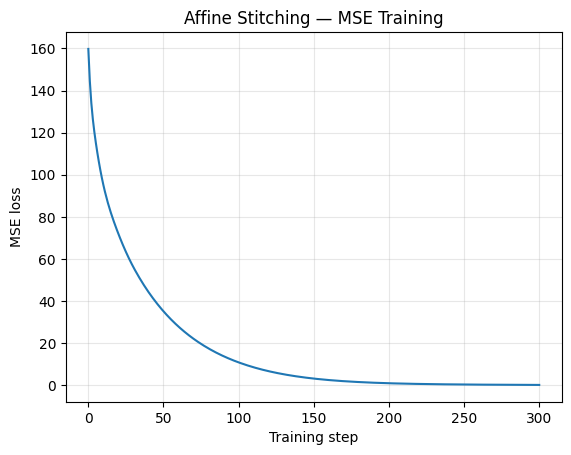

In [41]:

import matplotlib.pyplot as plt

plt.plot(losses)
plt.xlabel("Training step")
plt.ylabel("MSE loss")
plt.title("Affine Stitching — MSE Training")
plt.grid(alpha=0.3)
plt.show()
